# 03 — Track Re-identification สำหรับ video001

Notebook นี้ใช้ผล Face Detection ที่มีอยู่แล้ว เพื่อรวม `track_id` ที่แตกเป็นจำนวนมากให้กลับมาเป็น `person_id` ของคนจริง

Input:
- `dataset/yolo_face_detection/video001/detection.csv`
- `dataset/raw_videos/video001.webm`

Output:
- `dataset/reid/video001/track_samples/`
- `dataset/reid/video001/track_embeddings.npy`
- `dataset/reid/video001/track_embedding_index.csv`
- `dataset/reid/video001/track_person_map.csv`
- `dataset/reid/video001/reidentified_detection.csv`
- `dataset/reid/video001/person_summary.csv`

แนวคิด:
1. เลือกตัวอย่างหลายเฟรมต่อ track
2. Crop ใบหน้าจากวิดีโอ
3. ใช้ InsightFace recognition model สร้าง embedding
4. เฉลี่ย embedding ต่อ track
5. Cluster track embeddings
6. เพิ่ม `person_id` กลับเข้า detection.csv

> ไม่ต้อง Face Detect ใหม่ทั้งวิดีโอ

## Cell 1 — Path / Cache

In [1]:
import os
from pathlib import Path

PROJECT_ROOT = Path(r"D:\Face_detection")
VIDEO_ID = "video001"

VIDEO_PATH = PROJECT_ROOT / "dataset" / "raw_videos" / f"{VIDEO_ID}.webm"
DETECTION_CSV = PROJECT_ROOT / "dataset" / "yolo_face_detection" / VIDEO_ID / "detection.csv"

OUTPUT_ROOT = PROJECT_ROOT / "dataset" / "reid" / VIDEO_ID
SAMPLE_ROOT = OUTPUT_ROOT / "track_samples"
CACHE_ROOT = PROJECT_ROOT / "cache"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SAMPLE_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(CACHE_ROOT / "huggingface")
os.environ["TORCH_HOME"] = str(CACHE_ROOT / "torch")

print("VIDEO_PATH    :", VIDEO_PATH)
print("DETECTION_CSV :", DETECTION_CSV)
print("OUTPUT_ROOT   :", OUTPUT_ROOT)

if not VIDEO_PATH.exists():
    raise FileNotFoundError(VIDEO_PATH)

if not DETECTION_CSV.exists():
    raise FileNotFoundError(DETECTION_CSV)

VIDEO_PATH    : D:\Face_detection\dataset\raw_videos\video001.webm
DETECTION_CSV : D:\Face_detection\dataset\yolo_face_detection\video001\detection.csv
OUTPUT_ROOT   : D:\Face_detection\dataset\reid\video001


## Cell 2 — Environment

In [2]:
import sys
import numpy as np
import pandas as pd

print("Python :", sys.executable)
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)

Python : c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\python.exe
NumPy  : 2.5.2
Pandas : 3.0.5


## Cell 3 — Install dependencies

In [3]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-U",
    "insightface==1.0.1",
    "onnxruntime-gpu==1.29.0",
    "scikit-learn",
    "opencv-python",
    "pandas",
    "numpy",
    "matplotlib",
    "tqdm"
])

print("Dependencies ready")

Dependencies ready


## Cell 4 — Load detection.csv

In [4]:
det_df = pd.read_csv(DETECTION_CSV)

required_cols = {
    "frame_index", "track_id",
    "x1", "y1", "x2", "y2",
    "det_score"
}

missing = required_cols - set(det_df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

det_df["frame_index"] = det_df["frame_index"].astype(int)
det_df["track_id"] = det_df["track_id"].astype(int)

print("Detection rows :", len(det_df))
print("Tracks         :", det_df["track_id"].nunique())
print("Max frame      :", det_df["frame_index"].max())

track_stats = (
    det_df.groupby("track_id")
    .agg(
        detections=("frame_index", "count"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_x1=("x1", "mean"),
        mean_y1=("y1", "mean"),
        mean_x2=("x2", "mean"),
        mean_y2=("y2", "mean"),
        mean_conf=("det_score", "mean"),
    )
    .reset_index()
)

track_stats["span"] = (
    track_stats["last_frame"] - track_stats["first_frame"] + 1
)
track_stats["coverage"] = (
    track_stats["detections"] / track_stats["span"]
)

track_stats = track_stats.sort_values(
    "detections", ascending=False
).reset_index(drop=True)

display(track_stats.head(30))

Detection rows : 256620
Tracks         : 256
Max frame      : 178333


,track_id,detections,first_frame,last_frame,mean_x1,mean_y1,mean_x2,mean_y2,mean_conf,span,coverage
0,166,7507,129166,136672,480.865420,310.967843,619.837693,506.381172,0.826566,7507,1.0
1,167,7507,129166,136672,1303.350177,305.348618,1442.362292,500.349906,0.814418,7507,1.0
2,30,6312,6716,13027,841.375727,300.534614,980.366508,496.753490,0.826522,6312,1.0
3,149,6260,113571,119830,915.800665,314.962138,1051.055687,517.752747,0.815935,6260,1.0
4,66,6183,38727,44909,1305.113476,291.819384,1443.996254,489.918934,0.815682,6183,1.0
5,67,6183,38727,44909,512.013214,314.697549,653.424603,509.920127,0.827045,6183,1.0
6,97,4850,61794,66643,916.183348,300.406515,1053.144696,503.543036,0.818530,4850,1.0
7,186,4617,145898,150514,911.973088,309.102768,1045.843711,509.825119,0.819730,4617,1.0
8,107,4578,72804,77381,475.162346,307.588296,618.897273,504.289194,0.829947,4578,1.0
9,108,4578,72804,77381,1303.187297,306.253802,1443.385708,500.187554,0.821302,4578,1.0


## Cell 5 — Select sample frames per track

In [5]:
SAMPLES_PER_TRACK = 7
MIN_TRACK_DETECTIONS = 5

sample_rows = []

for track_id, group in det_df.groupby("track_id"):
    group = group.sort_values("frame_index").reset_index(drop=True)

    if len(group) < MIN_TRACK_DETECTIONS:
        continue

    n = min(SAMPLES_PER_TRACK, len(group))

    sample_positions = np.linspace(
        0,
        len(group) - 1,
        n
    ).astype(int)

    selected = group.iloc[np.unique(sample_positions)]

    for sample_rank, (_, row) in enumerate(selected.iterrows()):
        sample_rows.append({
            "track_id": int(track_id),
            "sample_rank": int(sample_rank),
            "frame_index": int(row["frame_index"]),
            "x1": float(row["x1"]),
            "y1": float(row["y1"]),
            "x2": float(row["x2"]),
            "y2": float(row["y2"]),
            "det_score": float(row["det_score"]),
        })

samples_df = pd.DataFrame(sample_rows)

print("Sample rows:", len(samples_df))
print("Tracks sampled:", samples_df["track_id"].nunique())

display(samples_df.head(20))

Sample rows: 1783
Tracks sampled: 255


,track_id,sample_rank,frame_index,x1,y1,x2,y2,det_score
0,0,0,0,529.128,305.736,671.765,498.087,0.833094
1,0,1,80,516.265,290.509,656.510,480.742,0.823723
2,0,2,161,525.411,318.616,666.055,507.073,0.827017
3,0,3,242,522.052,294.936,665.039,488.095,0.814286
4,0,4,323,523.774,297.341,665.592,496.284,0.830162
5,0,5,404,529.651,282.556,671.869,477.916,0.839706
6,0,6,485,521.020,295.635,663.986,492.935,0.831816
7,1,0,0,1269.474,276.933,1410.382,478.952,0.824791
8,1,1,80,1272.874,278.060,1415.439,490.995,0.826917
9,1,2,161,1257.036,281.079,1397.824,484.014,0.809546


## Cell 6 — Crop face samples

In [6]:
import cv2
from tqdm.auto import tqdm

FACE_MARGIN = 0.20
MIN_FACE_SIZE = 60

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f"เปิดวิดีโอไม่ได้: {VIDEO_PATH}")

sample_meta = []

for _, row in tqdm(
    samples_df.iterrows(),
    total=len(samples_df),
    desc="cropping track samples"
):
    frame_index = int(row["frame_index"])
    track_id = int(row["track_id"])

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    ret, frame = cap.read()

    if not ret or frame is None:
        continue

    h, w = frame.shape[:2]

    x1, y1, x2, y2 = map(
        float,
        [row["x1"], row["y1"], row["x2"], row["y2"]]
    )

    bw = x2 - x1
    bh = y2 - y1

    margin_x = bw * FACE_MARGIN
    margin_y = bh * FACE_MARGIN

    cx1 = max(0, int(round(x1 - margin_x)))
    cy1 = max(0, int(round(y1 - margin_y)))
    cx2 = min(w, int(round(x2 + margin_x)))
    cy2 = min(h, int(round(y2 + margin_y)))

    crop = frame[cy1:cy2, cx1:cx2]

    if crop.size == 0:
        continue

    ch, cw = crop.shape[:2]
    if min(ch, cw) < MIN_FACE_SIZE:
        continue

    track_dir = SAMPLE_ROOT / f"track_{track_id:03d}"
    track_dir.mkdir(parents=True, exist_ok=True)

    sample_path = track_dir / f"frame_{frame_index:08d}.jpg"

    cv2.imwrite(
        str(sample_path),
        crop,
        [cv2.IMWRITE_JPEG_QUALITY, 90]
    )

    sample_meta.append({
        "track_id": track_id,
        "frame_index": frame_index,
        "sample_path": str(sample_path.relative_to(PROJECT_ROOT)),
        "det_score": float(row["det_score"]),
    })

cap.release()

sample_meta_df = pd.DataFrame(sample_meta)

SAMPLE_META_CSV = OUTPUT_ROOT / "track_sample_metadata.csv"
sample_meta_df.to_csv(
    SAMPLE_META_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Saved samples:", len(sample_meta_df))
print("CSV:", SAMPLE_META_CSV)

display(sample_meta_df.head(20))

c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
cropping track samples: 100%|██████████| 1783/1783 [05:32<00:00,  5.36it/s]

Saved samples: 1755
CSV: D:\Face_detection\dataset\reid\video001\track_sample_metadata.csv


,track_id,frame_index,sample_path,det_score
0,0,0,dataset\reid\video001\track_samples\track_000\...,0.833094
1,0,80,dataset\reid\video001\track_samples\track_000\...,0.823723
2,0,161,dataset\reid\video001\track_samples\track_000\...,0.827017
3,0,242,dataset\reid\video001\track_samples\track_000\...,0.814286
4,0,323,dataset\reid\video001\track_samples\track_000\...,0.830162
5,0,404,dataset\reid\video001\track_samples\track_000\...,0.839706
6,0,485,dataset\reid\video001\track_samples\track_000\...,0.831816
7,1,0,dataset\reid\video001\track_samples\track_001\...,0.824791
8,1,80,dataset\reid\video001\track_samples\track_001\...,0.826917
9,1,161,dataset\reid\video001\track_samples\track_001\...,0.809546


## Cell 7 — Load InsightFace

In [7]:
import onnxruntime as ort
from insightface.app import FaceAnalysis

available = ort.get_available_providers()
print("Available providers:", available)

providers = (
    ["CUDAExecutionProvider", "CPUExecutionProvider"]
    if "CUDAExecutionProvider" in available
    else ["CPUExecutionProvider"]
)

app = FaceAnalysis(
    name="buffalo_l",
    providers=providers
)

app.prepare(
    ctx_id=0 if "CUDAExecutionProvider" in providers else -1,
    det_size=(640, 640)
)

print("InsightFace ready")

Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\ASUS FA507NUR/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\ASUS FA507NUR/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\ASUS FA507NUR/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\ASUS FA507NUR/.insightface\models\buffalo_l\genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUEx

## Cell 8 — Sample embeddings

In [8]:
embedding_rows = []
embedding_vectors = []

for _, row in tqdm(
    sample_meta_df.iterrows(),
    total=len(sample_meta_df),
    desc="face embeddings"
):
    image_path = PROJECT_ROOT / row["sample_path"]
    image = cv2.imread(str(image_path))

    if image is None:
        continue

    faces = app.get(image)

    if not faces:
        continue

    face = max(
        faces,
        key=lambda f: float(f.det_score)
    )

    emb = np.asarray(
        face.normed_embedding,
        dtype=np.float32
    ).reshape(-1)

    embedding_rows.append({
        "track_id": int(row["track_id"]),
        "frame_index": int(row["frame_index"]),
        "sample_path": row["sample_path"],
        "face_det_score": float(face.det_score),
        "embedding_index": len(embedding_vectors),
    })

    embedding_vectors.append(emb)

sample_embedding_df = pd.DataFrame(embedding_rows)

sample_embeddings = (
    np.stack(embedding_vectors)
    if embedding_vectors
    else np.empty((0, 512), dtype=np.float32)
)

print("Embedding samples:", len(sample_embedding_df))
print("Embedding shape  :", sample_embeddings.shape)

display(sample_embedding_df.head(20))

face embeddings:   0%|          | 0/1755 [00:00<?, ?it/s]c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\Lib\site-packages\insightface\utils\face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)
face embeddings: 100%|██████████| 1755/1755 [10:44<00:00,  2.72it/s]

Embedding samples: 1668
Embedding shape  : (1668, 512)


,track_id,frame_index,sample_path,face_det_score,embedding_index
0,0,0,dataset\reid\video001\track_samples\track_000\...,0.601793,0
1,0,80,dataset\reid\video001\track_samples\track_000\...,0.607529,1
2,0,161,dataset\reid\video001\track_samples\track_000\...,0.530601,2
3,0,242,dataset\reid\video001\track_samples\track_000\...,0.548118,3
4,0,323,dataset\reid\video001\track_samples\track_000\...,0.663138,4
5,0,404,dataset\reid\video001\track_samples\track_000\...,0.570098,5
6,0,485,dataset\reid\video001\track_samples\track_000\...,0.604920,6
7,1,0,dataset\reid\video001\track_samples\track_001\...,0.612036,7
8,1,80,dataset\reid\video001\track_samples\track_001\...,0.657249,8
9,1,161,dataset\reid\video001\track_samples\track_001\...,0.647789,9


## Cell 9 — Track-level embeddings

In [9]:
track_embedding_rows = []
track_embedding_vectors = []

for track_id, group in sample_embedding_df.groupby("track_id"):
    indices = group["embedding_index"].astype(int).to_numpy()
    embs = sample_embeddings[indices]

    mean_emb = embs.mean(axis=0)
    norm = np.linalg.norm(mean_emb)

    if norm > 0:
        mean_emb = mean_emb / norm

    track_embedding_rows.append({
        "track_id": int(track_id),
        "num_embedding_samples": len(embs),
        "track_embedding_index": len(track_embedding_vectors),
    })

    track_embedding_vectors.append(
        mean_emb.astype(np.float32)
    )

track_embedding_df = pd.DataFrame(track_embedding_rows)

track_embeddings = (
    np.stack(track_embedding_vectors)
    if track_embedding_vectors
    else np.empty((0, 512), dtype=np.float32)
)

print("Tracks with embeddings:", len(track_embedding_df))
print("Track embedding shape :", track_embeddings.shape)

display(track_embedding_df.head(20))

Tracks with embeddings: 251
Track embedding shape : (251, 512)


,track_id,num_embedding_samples,track_embedding_index
0,0,7,0
1,1,7,1
2,2,5,2
3,3,4,3
4,4,6,4
5,5,7,5
6,6,7,6
7,7,7,7
8,8,7,8
9,9,7,9


## Cell 10 — Save embeddings

In [10]:
TRACK_EMB_NPY = OUTPUT_ROOT / "track_embeddings.npy"
TRACK_EMB_INDEX_CSV = OUTPUT_ROOT / "track_embedding_index.csv"
SAMPLE_EMB_INDEX_CSV = OUTPUT_ROOT / "sample_embedding_index.csv"

np.save(TRACK_EMB_NPY, track_embeddings)

track_embedding_df.to_csv(
    TRACK_EMB_INDEX_CSV,
    index=False,
    encoding="utf-8-sig"
)

sample_embedding_df.to_csv(
    SAMPLE_EMB_INDEX_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(" -", TRACK_EMB_NPY)
print(" -", TRACK_EMB_INDEX_CSV)
print(" -", SAMPLE_EMB_INDEX_CSV)

Saved:
 - D:\Face_detection\dataset\reid\video001\track_embeddings.npy
 - D:\Face_detection\dataset\reid\video001\track_embedding_index.csv
 - D:\Face_detection\dataset\reid\video001\sample_embedding_index.csv


## Cell 11 — Similarity distribution

In [11]:
similarity_matrix = track_embeddings @ track_embeddings.T

upper_values = similarity_matrix[
    np.triu_indices_from(similarity_matrix, k=1)
]

print(
    pd.Series(upper_values).describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    31375.000000
mean         0.443201
std          0.385422
min         -0.079539
50%          0.544242
75%          0.842147
90%          0.903991
95%          0.924051
99%          0.952070
max          0.983899
dtype: float64


## Cell 12 — Cluster tracks

In [12]:
from sklearn.cluster import AgglomerativeClustering

DISTANCE_THRESHOLD = 0.35

clustering = AgglomerativeClustering(
    n_clusters=None,
    metric="cosine",
    linkage="average",
    distance_threshold=DISTANCE_THRESHOLD
)

person_labels = clustering.fit_predict(track_embeddings)

track_person_df = track_embedding_df.copy()
track_person_df["person_id"] = person_labels.astype(int)

person_order = (
    track_person_df.groupby("person_id")["track_id"]
    .min()
    .sort_values()
    .index
    .tolist()
)

person_remap = {
    old_id: new_id
    for new_id, old_id in enumerate(person_order)
}

track_person_df["person_id"] = (
    track_person_df["person_id"]
    .map(person_remap)
    .astype(int)
)

print("Estimated persons:", track_person_df["person_id"].nunique())

display(
    track_person_df.sort_values(
        ["person_id", "track_id"]
    ).head(100)
)

Estimated persons: 5


,track_id,num_embedding_samples,track_embedding_index,person_id
0,0,7,0,0
4,4,6,4,0
7,7,7,7,0
9,9,7,9,0
10,10,7,10,0
...,...,...,...,...
232,237,7,232,0
234,239,7,234,0
236,241,6,236,0
239,244,7,239,0


## Cell 13 — Merge track stats

In [13]:
track_person_df = track_person_df.merge(
    track_stats,
    on="track_id",
    how="left"
)

display(
    track_person_df[
        [
            "person_id",
            "track_id",
            "detections",
            "first_frame",
            "last_frame",
            "mean_x1",
            "mean_conf",
            "num_embedding_samples",
        ]
    ].sort_values(
        ["person_id", "first_frame"]
    ).head(100)
)

,person_id,track_id,detections,first_frame,last_frame,mean_x1,mean_conf,num_embedding_samples
0,0,0,486,0,485,524.160113,0.828854,7
4,0,4,52,593,644,504.173423,0.834700,6
7,0,7,639,726,1364,531.262865,0.828973,7
9,0,9,403,1365,1767,854.982618,0.824192,7
10,0,10,92,1768,1859,514.049087,0.832503,7
...,...,...,...,...,...,...,...,...
232,0,237,2463,172483,174945,491.697014,0.831385,7
234,0,239,1374,175279,176652,488.225357,0.835821,7
236,0,241,134,176653,176786,834.471754,0.828595,6
239,0,244,142,176849,176990,840.812183,0.825838,7


## Cell 14 — Person summary

In [14]:
person_summary = (
    track_person_df
    .groupby("person_id")
    .agg(
        num_tracks=("track_id", "count"),
        total_detections=("detections", "sum"),
        first_frame=("first_frame", "min"),
        last_frame=("last_frame", "max"),
        mean_conf=("mean_conf", "mean"),
    )
    .reset_index()
    .sort_values(
        "total_detections",
        ascending=False
    )
)

display(person_summary)

,person_id,num_tracks,total_detections,first_frame,last_frame,mean_conf
1,1,126,134346,0,178333,0.815695
0,0,103,116742,0,178333,0.828527
4,4,5,3462,645,178227,0.822536
2,2,14,1535,486,176848,0.667278
3,3,3,332,486,176848,0.798293


## Cell 15 — Preview samples per person

Person 0 | tracks=[0, 4, 7, 9, 10, 20, 22, 23, 25, 28, 30, 32, 35, 37, 38, 40, 41, 46, 49, 53]


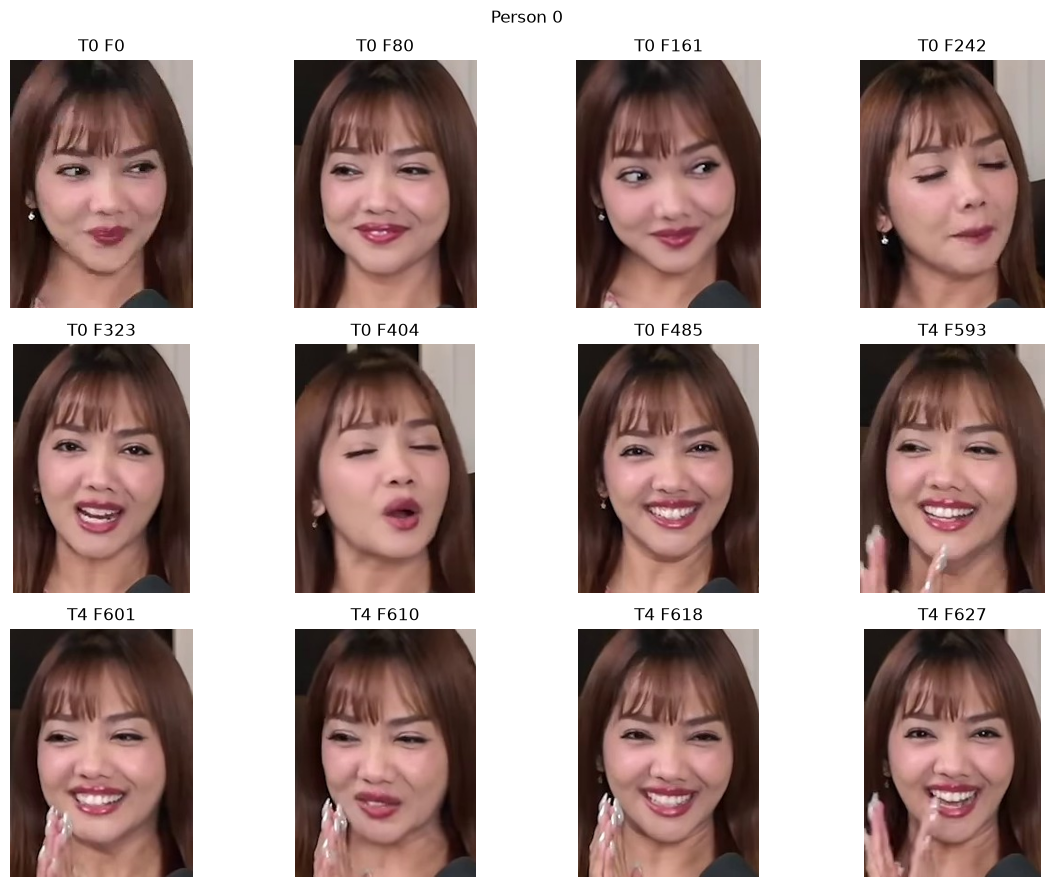

Person 1 | tracks=[1, 5, 8, 11, 21, 24, 27, 29, 31, 33, 34, 36, 39, 42, 43, 44, 47, 48, 50, 51]


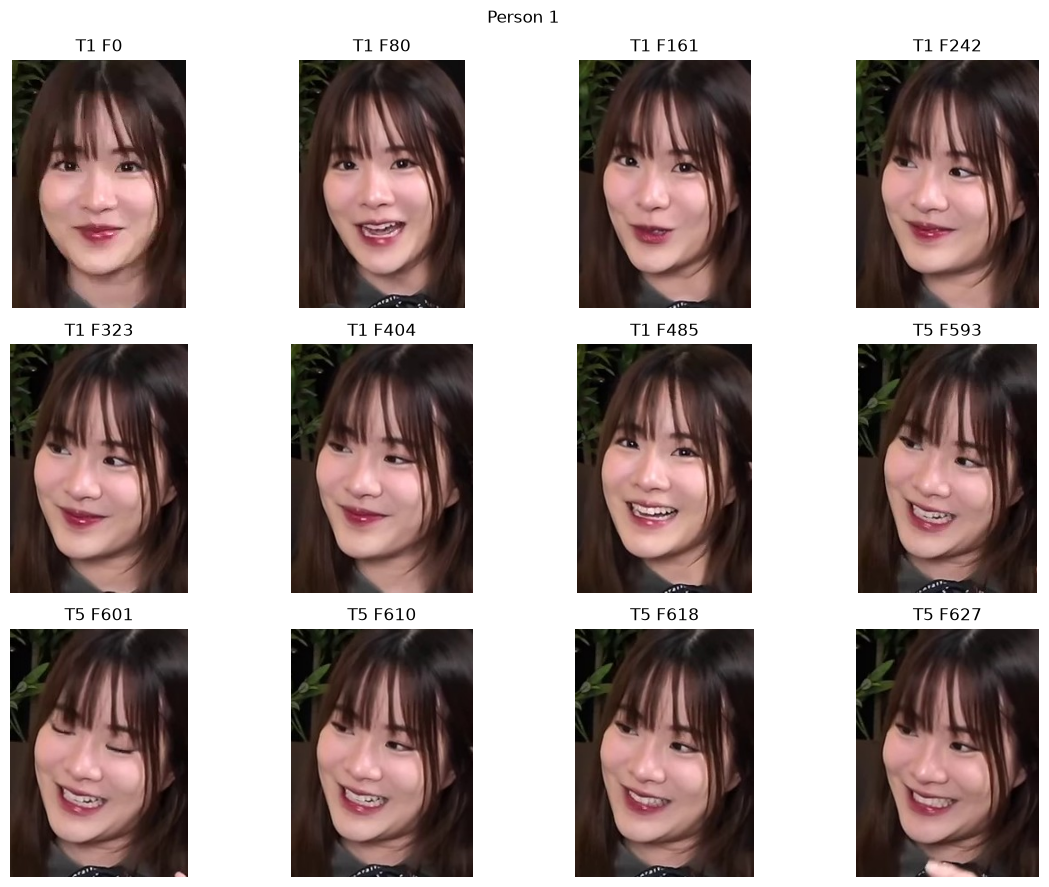

Person 2 | tracks=[2, 12, 26, 45, 58, 79, 101, 127, 156, 158, 159, 160, 183, 243]


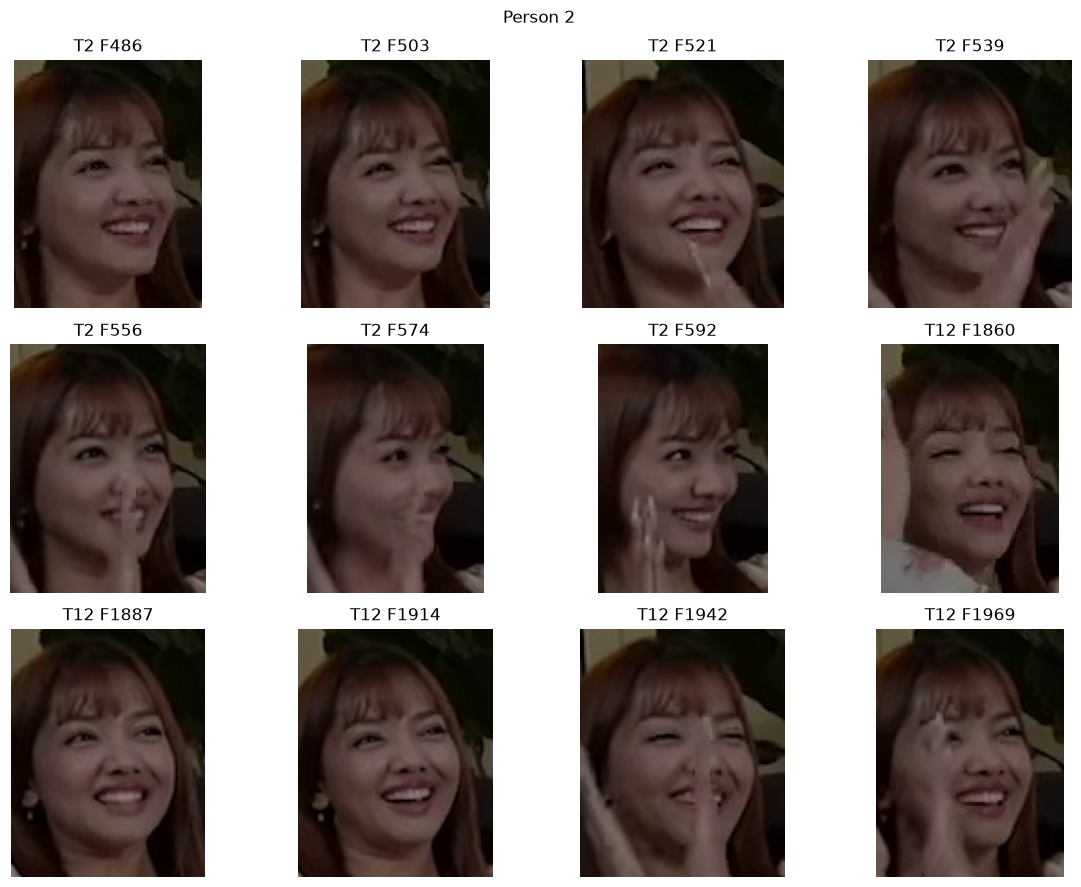

Person 3 | tracks=[3, 13, 242]


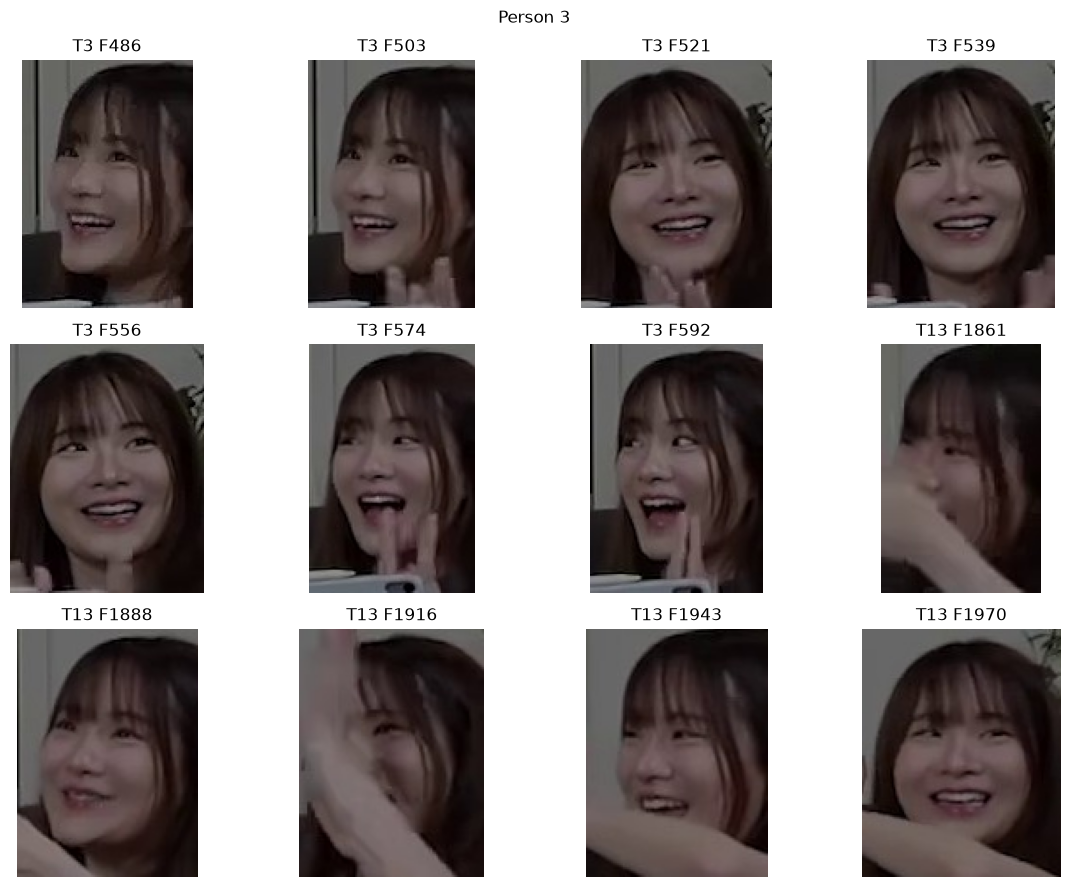

Person 4 | tracks=[6, 14, 247, 250, 253]


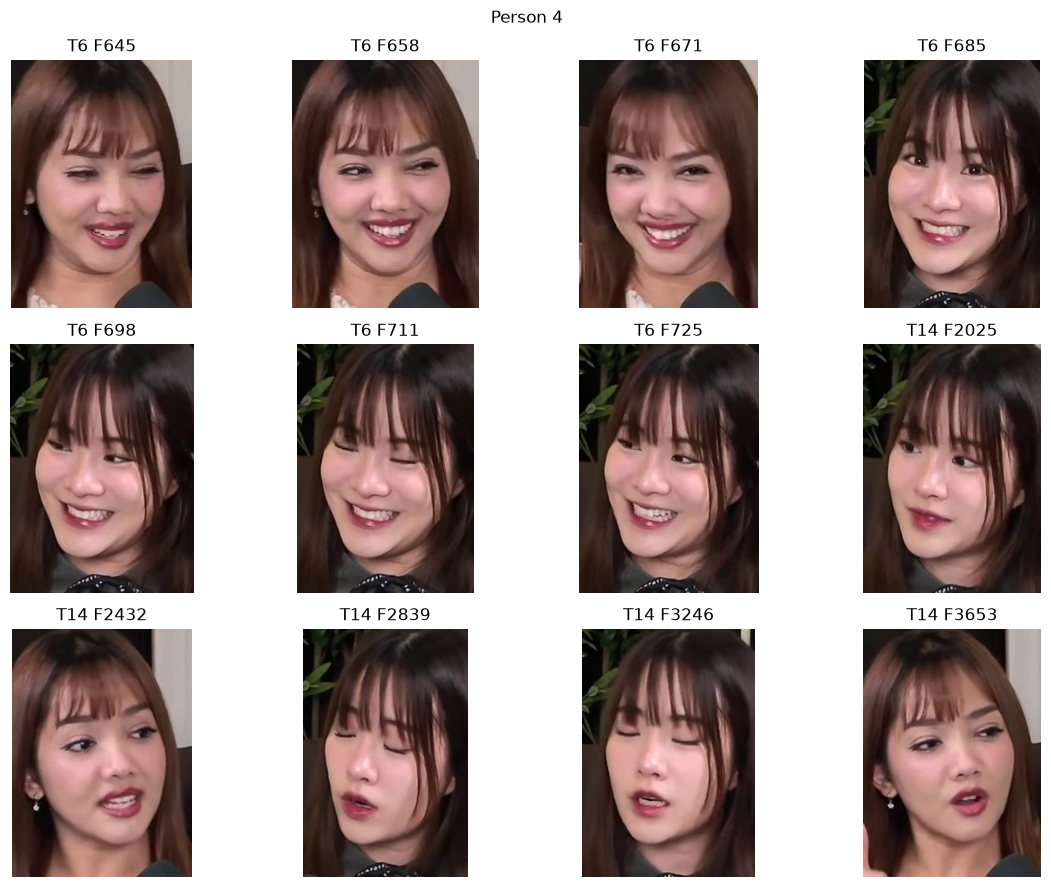

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

MAX_PERSONS_TO_SHOW = min(
    10,
    track_person_df["person_id"].nunique()
)

for person_id in sorted(
    track_person_df["person_id"].unique()
)[:MAX_PERSONS_TO_SHOW]:

    person_tracks = track_person_df[
        track_person_df["person_id"] == person_id
    ]["track_id"].tolist()

    person_samples = sample_meta_df[
        sample_meta_df["track_id"].isin(person_tracks)
    ].head(12)

    print(
        f"Person {person_id} | "
        f"tracks={person_tracks[:20]}"
    )

    if len(person_samples) == 0:
        continue

    cols = 4
    rows = int(np.ceil(len(person_samples) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, sample) in zip(
        axes,
        person_samples.iterrows()
    ):
        img_path = PROJECT_ROOT / sample["sample_path"]
        img = Image.open(img_path)

        ax.imshow(img)
        ax.set_title(
            f"T{int(sample['track_id'])} "
            f"F{int(sample['frame_index'])}"
        )
        ax.axis("off")

    plt.suptitle(f"Person {person_id}")
    plt.tight_layout()
    plt.show()

## Cell 16 — Save person map

In [16]:
TRACK_PERSON_MAP_CSV = OUTPUT_ROOT / "track_person_map.csv"
PERSON_SUMMARY_CSV = OUTPUT_ROOT / "person_summary.csv"

track_person_df.to_csv(
    TRACK_PERSON_MAP_CSV,
    index=False,
    encoding="utf-8-sig"
)

person_summary.to_csv(
    PERSON_SUMMARY_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(" -", TRACK_PERSON_MAP_CSV)
print(" -", PERSON_SUMMARY_CSV)

Saved:
 - D:\Face_detection\dataset\reid\video001\track_person_map.csv
 - D:\Face_detection\dataset\reid\video001\person_summary.csv


## Cell 17 — Add person_id back to detection.csv

In [17]:
reid_df = det_df.merge(
    track_person_df[
        ["track_id", "person_id"]
    ],
    on="track_id",
    how="left"
)

REID_DETECTION_CSV = OUTPUT_ROOT / "reidentified_detection.csv"

reid_df.to_csv(
    REID_DETECTION_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Rows:", len(reid_df))
print(
    "Person IDs:",
    sorted(
        reid_df["person_id"]
        .dropna()
        .unique()
        .tolist()
    )
)
print("Saved:", REID_DETECTION_CSV)

display(reid_df.head(20))

Rows: 256620
Person IDs: [0.0, 1.0, 2.0, 3.0, 4.0]
Saved: D:\Face_detection\dataset\reid\video001\reidentified_detection.csv


,video_id,frame_index,timestamp_seconds,track_id,face_index,x1,y1,x2,y2,face_width,face_height,det_score,person_id
0,video001,0,0.000000,0,0,529.128,305.736,671.765,498.087,142.637,192.351,0.833094,0.0
1,video001,0,0.000000,1,1,1269.474,276.933,1410.382,478.952,140.908,202.019,0.824791,1.0
2,video001,1,0.033367,0,0,529.254,305.274,671.930,497.819,142.676,192.545,0.834487,0.0
3,video001,1,0.033367,1,1,1269.540,275.139,1410.256,479.024,140.716,203.885,0.826267,1.0
4,video001,2,0.066733,0,0,528.629,305.161,671.965,497.940,143.336,192.779,0.834542,0.0
5,video001,2,0.066733,1,1,1270.542,273.439,1410.241,480.312,139.699,206.874,0.825334,1.0
6,video001,3,0.100100,0,0,528.470,305.528,671.986,497.878,143.516,192.349,0.835783,0.0
7,video001,3,0.100100,1,1,1270.974,271.983,1411.374,481.624,140.400,209.641,0.826308,1.0
8,video001,4,0.133467,0,0,528.339,304.176,671.636,497.745,143.297,193.569,0.832522,0.0
9,video001,4,0.133467,1,1,1271.542,268.377,1411.490,481.465,139.948,213.088,0.826028,1.0


In [18]:
# ============================================================
# QA — ตรวจ Person ID
# ============================================================

print("จำนวน Person:", reid_df["person_id"].nunique())

person_stats = (
    reid_df
    .dropna(subset=["person_id"])
    .groupby("person_id")
    .agg(
        detections=("frame_index", "count"),
        tracks=("track_id", "nunique"),
        first_frame=("frame_index", "min"),
        last_frame=("frame_index", "max"),
        mean_x1=("x1", "mean"),
        mean_x2=("x2", "mean"),
        mean_conf=("det_score", "mean"),
    )
    .reset_index()
)

person_stats["person_id"] = (
    person_stats["person_id"].astype(int)
)

display(person_stats)

จำนวน Person: 5


,person_id,detections,tracks,first_frame,last_frame,mean_x1,mean_x2,mean_conf
0,0,116742,103,0,178333,611.934475,752.361868,0.828153
1,1,134346,126,0,178333,1138.779999,1275.925176,0.815786
2,2,1535,14,486,176848,472.537974,548.828057,0.736045
3,3,332,3,486,176848,1350.665542,1423.378575,0.795326
4,4,3462,5,645,178227,876.834681,1016.681496,0.820518


# ขั้นต่อไป

เมื่อ QA แล้วว่า `person_id` ถูกต้อง ให้ใช้:

`dataset/reid/video001/reidentified_detection.csv`

แทน `detection.csv` เดิมใน Mouth Extraction

จากนั้น Mouth Extraction จะจัดข้อมูลตาม `person_id` แทน `track_id`